# FCTD processing with modfish

End-to-end processing of one FCTD deployment, from `.modraw` files to the L1 and depth-gridded products, with T-C corrections and the microconductivity gain fitted on the deployment's own data.
To run it on another deployment, point the settings cell at its raw files and check the pressure bands at the top of section 4 against its depth range.
This copy was executed on MOTIVE deployment `25_1208_d08_motiveb` (SBE49 serial 0537, one profile to 1491 dbar), with the thermal-mass fit on `25_1210_d10_deep_station_A` (section 4 says why).

**Install** (once):

```
git clone https://github.com/modscripps/modfish.git
cd modfish
uv sync --group examples
uv run python -m ipykernel install --user --name modfish
```

**Run**: copy the deployment's `.modraw` files into a local directory (for example `examples/data/raw/`, which git ignores), edit the settings cell below, open this notebook with the `modfish` kernel and run all cells.
Outputs (L0 netCDF, products, the fitted `fctd.yml`) go to `work_dir`.


## 1. Setup

Imports, logging and plot defaults.
`process_deployment` reports progress through `logging` at INFO level, including the message when it skips a deployment whose outputs already exist.

In [1]:
import logging
from pathlib import Path

import gsw
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import yaml
from scipy import signal

from modfish import fctd, modraw, tc
from modfish.chi import ChiParams
from modfish.chi import config as chi_config
from modfish.chi.fit import fit_gain_casts
from modfish.chi.load import load_c1

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (8, 4)})

### Settings

Edit this cell for your deployment.
`raw_dir` holds the `.modraw` files of one deployment.
`work_dir` receives `l0/`, `proc/` and `fctd.yml`.
`latitude_fallback` is used, with a warning, only when the record has no GPS fix (otherwise `make_l1` raises).
`tm_raw_dir` points at a second deployment of the same sensor for the thermal-mass fit. Leave it `None` to fit on this deployment.

In [2]:
raw_dir = Path("data/raw")          # .modraw files of one deployment
work_dir = Path("data")             # l0/, proc/ and fctd.yml go here
name = "d08"                        # deployment name in the output file names
latitude_fallback = None            # degrees_north; None: the record must have GPS
template = Path("fctd_example.yml") # template config from modfish/examples

# Second deployment of the same sensor for the thermal-mass fit, or None to fit on
# this deployment. data/d10/raw is MOTIVE d10, specific to this executed copy.
tm_raw_dir = Path("data/d10/raw")
tm_name = "d10"

l0_dir = work_dir / "l0"
proc_dir = work_dir / "proc"
raw_files = sorted(raw_dir.glob("*.modraw"))
if not raw_files:
    raise FileNotFoundError(f"no .modraw files in {raw_dir}")
print(f"{len(raw_files)} raw files in {raw_dir}")



4 raw files in data/raw


### Parameters that do not carry over from MOTIVE

These are sensor, probe or deployment specific. Fit them on your own data (sections 4 and 5) or check them before use.

- T-C `lag`, `tau_t` and `lowpass`. The template ships them as a no-op.
- Thermal mass, `alpha` and `beta`, or a `thermal_mass_profile`.
- `chi.gain`, fitted per product. `chi.enabled: true` without a gain raises.
- `grid.closure_exclude_flags`. MOTIVE products set 128 (`rrho_capped`) where the cap follows salinity-gradient noise. The template default 0 excludes nothing.
- The chi noise floor. `builtin:fctd_2026` is built from MOTIVE 2024 and 2025 FCTD records. `add_chi` warns when a record's floor at 20 Hz is more than 10x higher.

MOTIVE values for SBE49 0537 (motive-cruise-proc `config.yml`) are printed next to the fitted values as reference only.

In [3]:
# Reference only: MOTIVE FCTD1, SBE49 0537 (motive-cruise-proc config.yml).
REF = dict(lag=0.03, tau_t=0.05, lowpass=5.0, gain=7.49)
# fleet thermal-mass product alpha*tau [s] against pressure [dbar], at beta = 1/12 s
REF_TM_PROFILE = dict(
    p=[75.0, 125.0, 175.0, 250.0, 350.0, 450.0, 600.0, 800.0, 1000.0],
    product=[0.120, 0.124, 0.100, 0.118, 0.154, 0.169, 0.195, 0.232, 0.237],
)

## 2. Convert to L0

`modraw.convert` writes one netCDF file per `.modraw` file to `l0_dir`, named after the input stem.
A file that fails to read is logged and skipped. Existing outputs are skipped unless `overwrite=True`.

In [4]:
modraw.convert(raw_files, l0_dir)
l0_files = [l0_dir / f"{f.stem}.nc" for f in raw_files]
missing = [f.name for f in l0_files if not f.exists()]
l0_files = [f for f in l0_files if f.exists()]
print(f"{len(l0_files)} L0 files in {l0_dir}, {len(missing)} failed: {missing}")

4 L0 files in data/l0, 0 failed: []


### Quick look at one L0 file

Each L0 file is a `DataTree` with one group per stream (`ctd`, `efe`, `gps`, and others where present).
The SBE49 calibration coefficients and the serial number sit in `ctd.attrs`.

In [5]:
def summarize_tree(tree):
    """One line per group: dimensions and variable names."""
    for node in tree.subtree:
        ds = node.to_dataset(inherit=False)
        if not ds.data_vars:
            continue
        dims = ", ".join(f"{k} {v}" for k, v in ds.sizes.items())
        print(f"{node.path:8s} ({dims}): {', '.join(ds.data_vars)}")


with xr.open_datatree(l0_files[0]) as l0:
    summarize_tree(l0)
    a = l0["ctd"].attrs
    print(f"\nserial {a.get('serialnum')}, vehicle {a.get('vehicle')}, survey {a.get('survey')}")
    print(f"ctd time {l0['ctd'].time.values[0]} to {l0['ctd'].time.values[-1]}")


/        (block 16360): laptop_time, block_time, block_tag
/ctd     (time 5908): p, t, c, t_raw, c_raw, p_raw, pt_raw
/efe     (time 120560): t1, t2, f1, c1, a1, a2, a3
/ecop    (time 11897): bb, chla, fdom, bb_raw, chla_raw, fdom_raw
/gps     (time 377): lat, lon

serial 0537, vehicle FCTD1, survey 25_1208_d08_motiveb
ctd time 2025-12-08T13:36:54.310000000 to 2025-12-08T13:43:03.501000000


## 3. First pass, corrections off

`process_deployment` with the template config: T-C corrections are a no-op and chi is disabled.
`make_l1` corrects `t` and `c` in place, so this pass gives the uncorrected pair the T-C fits in section 4 start from.
`overwrite=True` reprocesses on every run. Without it, `process_deployment` returns the existing files unchanged.

In [6]:
cfg0 = fctd.FCTDConfig.from_yaml(template)
cfg0.latitude_fallback = latitude_fallback
l1_pass1, grid_pass1 = fctd.process_deployment(l0_files, proc_dir, f"{name}_pass1", config=cfg0, overwrite=True)


def load_l1(path):
    """L1 `ctd` and `casts` groups, loaded into memory."""
    with xr.open_datatree(path) as tree:
        ctd = tree["ctd"].to_dataset().load()
        casts = tree["casts"].to_dataset().load()
    return ctd, casts


def cast_table(ctd, casts):
    """Per-cast direction, pressure range and median fall rate."""
    for c, d in zip(casts.cast.values, casts.direction.values, strict=True):
        m = ctd.cast.values == c
        p = ctd.p.values[m]
        w = np.nanmedian(np.abs(ctd.dPdt.values[m]))
        print(f"cast {c:3d} {d:4s} {m.sum():6d} samples, {np.nanmin(p):7.1f} to {np.nanmax(p):7.1f} dbar, |dP/dt| {w:.2f} dbar/s")


ctd, casts = load_l1(l1_pass1)
serial = ctd.attrs.get("serialnum")
n_down = int((casts.direction.values == "down").sum())
print(f"serial {serial}: {casts.sizes['cast']} casts, {n_down} down, {casts.sizes['cast'] - n_down} up")
cast_table(ctd, casts)

WARNING modfish.fctd.concat: FCTD25_12_08_133647.nc and FCTD25_12_08_134303.nc overlap by 20.4 s
WARNING modfish.fctd.concat: FCTD25_12_08_134303.nc and FCTD25_12_08_134911.nc overlap by 20.5 s
WARNING modfish.fctd.concat: FCTD25_12_08_134911.nc and FCTD25_12_08_135519.nc overlap by 20.1 s
INFO modfish.fctd.casts: find_casts: 2 candidate run(s) rejected by min_range=10.0/min_duration=10.0


serial 0537: 4 casts, 2 down, 2 up
cast   1 down   3938 samples,     0.8 to  1012.0 dbar, |dP/dt| 3.91 dbar/s
cast   2 down   2768 samples,  1014.5 to  1488.3 dbar, |dP/dt| 2.86 dbar/s
cast   3 up     6022 samples,    51.8 to  1491.0 dbar, |dP/dt| 3.71 dbar/s
cast   4 up      709 samples,    15.1 to    49.6 dbar, |dP/dt| 0.72 dbar/s


### Down/up separation, uncorrected

Salinity against temperature for down and up casts below 50 dbar.
Without corrections the two directions separate where the temperature gradient is strong.
Section 4 fits the corrections that bring them together.


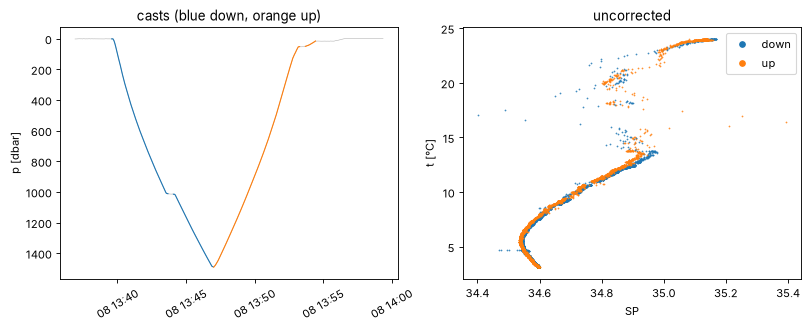

In [7]:
def plot_ts(ax, ds, casts, pmin=50, title=""):
    """SP against t below `pmin`, colored by cast direction."""
    direction = dict(zip(casts.cast.values, casts.direction.values, strict=True))
    for d, color in [("down", "C0"), ("up", "C1")]:
        ids = [c for c, v in direction.items() if v == d]
        m = np.isin(ds.cast.values, ids) & (ds.p.values > pmin)
        ax.plot(ds.SP.values[m], ds.t.values[m], ".", ms=1, color=color, label=d)
    ax.set(xlabel="SP", ylabel="t [°C]", title=title)
    ax.legend(markerscale=10)


fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for c, d in zip(casts.cast.values, casts.direction.values, strict=True):
    m = ctd.cast.values == c
    ax0.plot(ctd.time.values[m], ctd.p.values[m], color="C0" if d == "down" else "C1", lw=1)
ax0.plot(ctd.time.values, ctd.p.values, color="0.7", lw=0.5, zorder=0)
ax0.invert_yaxis()
ax0.set(ylabel="p [dbar]", title="casts (blue down, orange up)")
ax0.tick_params(axis="x", labelrotation=30)
plot_ts(ax1, ctd, casts, title="uncorrected")

## 4. T-C fitting

Three steps of the T-C chain in `tc.correct` are fitted here: a zero-phase low-pass on `t` and `c` (`lowpass`), the thermistor response and sensor lag on `t` (`tau_t`, `lag`), and the thermal-mass recursion on `c` (`alpha`, `beta`).
All fits below run on the first-pass `ctd` group.
The pressure bands are settings. The lag map needs a band with temperature gradient that the casts cover. The thermal-mass score needs a band that both casts of a down/up pair cover.
Shallower deployments need shallower bands.
When a shipboard rosette cast sits next to a fish profile, `tc.rosette_rms` scores the thermal-mass map against it and can replace `downup_separation`.


In [8]:
LAG_PBAND = (200, 400)    # dbar, band for the (lag, tau_t) salinity-roughness map
TM_PBAND = (50, 400)      # dbar, band for the down/up separation
TBIN = 0.05               # degC, temperature bins for the down/up separation
LOWPASS_CANDIDATES = [3.0, 4.0, 5.0, 6.0]  # Hz
MIN_CROSSING_CASTS = 5    # fewer casts with a coherence crossing make the low-pass pick a weak constraint


def check_minimum(cm, dims, units):
    """Location of a cost-map minimum, with a warning when it is on the grid edge or the map is flat."""
    i = cm.cost.argmin(...)
    best = {d: float(cm[d].values[int(i[d])]) for d in dims}
    edge = [d for d in dims if int(i[d]) in (0, cm.sizes[d] - 1)]
    ratio = float(cm.cost.max() / cm.cost.min())
    print("minimum at " + ", ".join(f"{d} {best[d]:.3g} {u}" for d, u in zip(dims, units, strict=True))
          + f", cost {float(cm.cost.min()):.3g}, max/min {ratio:.1f}")
    if edge:
        print(f"WARNING: minimum on the grid edge in {edge}; widen the grid or check the band")
    if ratio < 1.1:
        print("WARNING: map nearly flat (max/min < 1.1); the data do not constrain these parameters")
    return best


### Lag from cross-correlation

`find_lags` low-passes `t` and `c` at 4 Hz, differences them and cross-correlates them in 80-sample windows.
It runs per cast, on casts with at least 200 samples.
The lag it returns is the delay of `t` behind `c` from the thermistor response and the sensor separation together, so it constrains the sum `lag + tau_t`.
The cost map below splits the sum.

In [9]:
lag_rows = []
for c in casts.cast.values:
    sub = ctd.where(ctd.cast == c, drop=True)
    if sub.sizes["time"] < 200:
        continue
    out = tc.find_lags(sub, lowpass=4.0)
    lag_rows.append(out.lag.values)
    print(f"cast {c}: {out.sizes['segment']} windows, median lag {np.nanmedian(out.lag.values):.3f} s")
lag_xcorr = float(np.nanmedian(np.concatenate(lag_rows)))
print(f"median over all windows: {lag_xcorr:.3f} s (constrains lag + tau_t)")

INFO modfish.tc.estimate: 3938 scans, 98 segments
INFO modfish.tc.estimate: 2768 scans, 69 segments
INFO modfish.tc.estimate: 6022 scans, 150 segments


cast 1: 97 windows, median lag 0.069 s
cast 2: 68 windows, median lag 0.066 s


INFO modfish.tc.estimate: 709 scans, 17 segments


cast 3: 149 windows, median lag 0.068 s
cast 4: 16 windows, median lag 0.047 s
median over all windows: 0.067 s (constrains lag + tau_t)


### Low-pass cutoff from T-C coherence

The `tau_t` term amplifies `t` toward high frequency, so the chain needs a low-pass ahead of it.
The cutoff sits below the frequency where `t` and `c` stop covarying.
Per cast, the squared coherence of the uncorrected pair (128-sample segments, no overlap) is compared with its 95 % significance level, `1 - 0.05**(1/(n - 1))` for `n` segments.
The pressure window per cast follows motive-cruise-proc drafts/04 (the `add_tcfit_default` ranges): 500 dbar to the cast's maximum pressure for casts deeper than 1000 dbar, 200 dbar for casts deeper than 300 dbar, 50 dbar otherwise.
Casts with fewer than 4 segments in their window are skipped.
The rule picks the largest of 3, 4, 5 and 6 Hz below the median first crossing over the casts that cross. Casts that never cross drop out of the median.


cast 1: below 500 dbar, 18 segments, 95 % level 0.16, first crossing 5.58 Hz
cast 2: below 500 dbar, 21 segments, 95 % level 0.14, first crossing 2.36 Hz
cast 3: below 500 dbar, 34 segments, 95 % level 0.09, first crossing 6.94 Hz
cast 4: fewer than 4 segments below 50 dbar, skipped
3 casts used, 3 cross, 0 never cross
median crossing 5.58 Hz -> lowpass 5.0 Hz (MOTIVE reference 5.0 Hz)


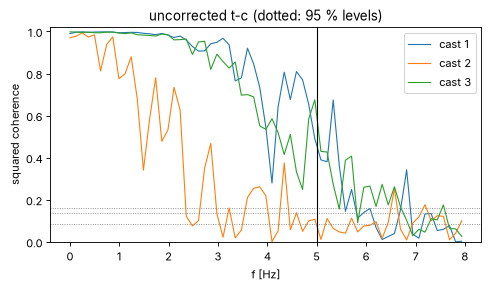

In [10]:
def coherence_window(pmax):
    """Lower pressure bound [dbar] of the coherence window for a cast reaching `pmax`."""
    return 500.0 if pmax > 1000 else 200.0 if pmax > 300 else 50.0


fs = 1 / (np.median(np.diff(ctd.time.values).astype("int64")) / 1e9)
NSEG = 128
crossings, coh_curves = [], []
for c in casts.cast.values:
    in_cast = ctd.cast.values == c
    pmin_c = coherence_window(np.nanmax(ctd.p.values[in_cast]))
    m = in_cast & (ctd.p.values > pmin_c)
    n = int(m.sum()) // NSEG
    if n < 4:
        print(f"cast {c}: fewer than 4 segments below {pmin_c:.0f} dbar, skipped")
        continue
    f, coh = signal.coherence(ctd.t.values[m], ctd.c.values[m], fs=fs, nperseg=NSEG, noverlap=0, detrend="linear")
    level = 1 - 0.05 ** (1 / (n - 1))
    below = np.flatnonzero((coh < level) & (f > 0))
    fx = f[below[0]] if below.size else np.nan
    crossings.append(fx)
    coh_curves.append((c, f, coh, level))
    print(f"cast {c}: below {pmin_c:.0f} dbar, {n} segments, 95 % level {level:.2f}, first crossing "
          + (f"{fx:.2f} Hz" if np.isfinite(fx) else "none below Nyquist"))

crossings = np.array(crossings)
n_cross = int(np.isfinite(crossings).sum())
print(f"{len(crossings)} casts used, {n_cross} cross, {len(crossings) - n_cross} never cross")
f_cross = np.nanmedian(crossings) if n_cross else np.inf
below_cross = [f for f in LOWPASS_CANDIDATES if f < f_cross]
lowpass = max(below_cross) if below_cross else min(LOWPASS_CANDIDATES)
if not below_cross:
    print(f"WARNING: median crossing {f_cross:.2f} Hz is below every candidate; using {lowpass} Hz")
if n_cross < MIN_CROSSING_CASTS:
    print(f"WARNING: only {n_cross} casts cross; the low-pass pick is a weak constraint")
print(f"median crossing {f_cross:.2f} Hz -> lowpass {lowpass} Hz (MOTIVE reference {REF['lowpass']} Hz)")

fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
for c, f, coh, level in coh_curves:
    ax.plot(f, coh, lw=1, label=f"cast {c}")
    ax.axhline(level, color="0.5", ls=":", lw=0.8)
ax.axvline(lowpass, color="k", lw=1)
ax.set(xlabel="f [Hz]", ylabel="squared coherence", ylim=(0, 1.02), title="uncorrected t-c (dotted: 95 % levels)")
ax.legend();


On d08 the pick rests on three casts of a single profile (down 0 to 1012 dbar, down 1014 to 1488 dbar, up 1491 to 52 dbar). Their crossings range from 2.36 to 6.94 Hz, so it is a weak constraint.
MOTIVE chose 5 Hz from ten down and ten up casts on each of d09 and d12 (motive-cruise-proc drafts/04).
On your own data, check the warning above and the spread of the crossings before accepting the pick.


### Lag and thermistor time constant

`lag_tau_cost_map` applies `tc.correct` at every `(lag, tau_t)` grid pair, recomputes salinity and scores it by `salinity_roughness`, the rms second difference of salinity over `LAG_PBAND`.
A mismatched pair leaves spikes in salinity, so the minimum is the joint estimate.
The dashed line is `lag + tau_t` equal to the cross-correlation lag above, an independent constraint on the sum.

minimum at lag 0.035 s, tau_t 0.05 s, cost 0.000716, max/min 9.1


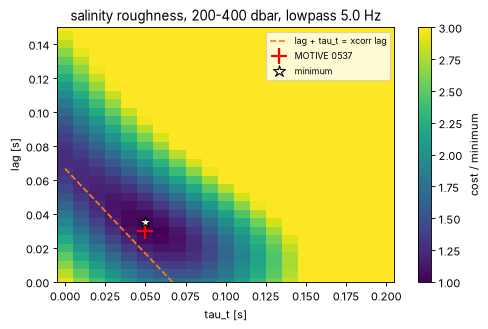

In [11]:
lags = np.arange(0, 0.151, 0.005)
taus_t = np.arange(0, 0.201, 0.01)
cm_lag = tc.lag_tau_cost_map(ctd, lags, taus_t, lowpass=lowpass, pmin=LAG_PBAND[0], pmax=LAG_PBAND[1])
best = check_minimum(cm_lag, ["lag", "tau_t"], ["s", "s"])
lag, tau_t = best["lag"], best["tau_t"]

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
pc = ax.pcolormesh(cm_lag.tau_t, cm_lag.lag, cm_lag.cost / cm_lag.cost.min(), vmin=1, vmax=3, cmap="viridis")
fig.colorbar(pc, ax=ax, label="cost / minimum")
ax.plot(taus_t, lag_xcorr - taus_t, color="C1", ls="--", lw=1.5, label="lag + tau_t = xcorr lag")
ax.plot(REF["tau_t"], REF["lag"], "r+", ms=14, mew=2, label="MOTIVE 0537")
ax.plot(tau_t, lag, "*", color="w", mec="k", ms=11, label="minimum")
ax.set(xlabel="tau_t [s]", ylabel="lag [s]", ylim=(lags[0], lags[-1]),
       title=f"salinity roughness, {LAG_PBAND[0]}-{LAG_PBAND[1]} dbar, lowpass {lowpass} Hz")
ax.legend(loc="upper right", fontsize=8);


### Thermal mass

The thermal-mass fit scores `(alpha, tau)` pairs, `beta = 1/tau`, by `downup_separation`: Morison's mean absolute salinity difference between a down cast and the up cast that follows it, in 0.05 °C temperature bins over `TM_PBAND`.
It runs on `t` and `c` already corrected for lag, `tau_t` and low-pass with the values above.
Only a down cast directly followed by an up cast, both with data in the band, forms a pair.

With fewer than 10 pairs the fitted `alpha` and `beta` are a placeholder for your own data.
Repeat the fit on a deployment with many down/up pairs before trusting them.

In [12]:
def with_sp(ds):
    """Recompute practical salinity from `c`, `t`, `p`."""
    return ds.assign(SP=("time", gsw.SP_from_C(10 * ds.c.data, ds.t.data, ds.p.data)))


def temperature_bins(ds):
    return np.arange(np.floor(float(ds.t.min()) / TBIN) * TBIN, float(ds.t.max()) + TBIN, TBIN)


def tm_cost(ds, casts, tbins):
    return tc.downup_separation(ds, casts, tbins, pmin=TM_PBAND[0], pmax=TM_PBAND[1]).attrs["mean"]


base = with_sp(tc.correct(ctd, lag=lag, tau_t=tau_t, lowpass=lowpass, thermal_mass=False))
sep = tc.downup_separation(base, casts, temperature_bins(base), pmin=TM_PBAND[0], pmax=TM_PBAND[1])
print(f"{name}: {sep.sizes['pair']} down/up pairs with data in {TM_PBAND[0]}-{TM_PBAND[1]} dbar")

d08: 0 down/up pairs with data in 50-400 dbar


On d08 the fish paused near 1012 dbar on the way down, so the cast detector split the profile into two down casts (0 to 1012 and 1014 to 1488 dbar).
The only down cast followed by an up cast is the deep one, with no data in 50 to 400 dbar, so d08 has no down/up pair in the band and its thermal-mass map is undefined.
The fit below uses `25_1210_d10_deep_station_A` instead (`tm_raw_dir`), the same SBE49 0537, with the lag, `tau_t` and low-pass fitted on d08.
With `tm_raw_dir = None` the fit runs on the deployment set at the top.

In [13]:
if tm_raw_dir is None:
    tm_ctd, tm_casts = ctd, casts
else:
    tm_work = work_dir / tm_name
    tm_raw = sorted(Path(tm_raw_dir).glob("*.modraw"))
    if not tm_raw:
        raise FileNotFoundError(
            f"no .modraw files in tm_raw_dir={tm_raw_dir}; set tm_raw_dir = None in the settings cell "
            "to fit the thermal mass on your own deployment"
        )
    modraw.convert(tm_raw, tm_work / "l0")
    tm_l0 = [tm_work / "l0" / f"{f.stem}.nc" for f in tm_raw]
    tm_l0 = [f for f in tm_l0 if f.exists()]
    cfg_tm = fctd.FCTDConfig.from_yaml(template)
    cfg_tm.latitude_fallback = latitude_fallback
    cfg_tm.groups = ("ctd", "gps")   # skip the efe stream, not needed here
    l1_tm, _ = fctd.process_deployment(tm_l0, tm_work / "proc", f"{tm_name}_pass1", config=cfg_tm, overwrite=True)
    tm_ctd, tm_casts = load_l1(l1_tm)
    tm_serial = tm_ctd.attrs.get("serialnum")
    print(f"{tm_name}: serial {tm_serial}, {tm_casts.sizes['cast']} casts")
    cast_table(tm_ctd, tm_casts)
    if tm_serial != serial:
        print(f"WARNING: {tm_name} has serial {tm_serial}, {name} has {serial}; thermal mass is sensor specific")

tm_base = with_sp(tc.correct(tm_ctd, lag=lag, tau_t=tau_t, lowpass=lowpass, thermal_mass=False))
tm_tbins = temperature_bins(tm_base)
tm_sep0 = tc.downup_separation(tm_base, tm_casts, tm_tbins, pmin=TM_PBAND[0], pmax=TM_PBAND[1])
n_pairs = tm_sep0.sizes["pair"]
print(f"{n_pairs} down/up pairs in {TM_PBAND[0]}-{TM_PBAND[1]} dbar, separation without thermal mass {tm_sep0.attrs['mean']:.4f}")
if n_pairs == 0:
    raise ValueError("no down/up pair in TM_PBAND; set tm_raw_dir or change TM_PBAND")


WARNING modfish.modraw.reader: file has 1130 EFE4 blocks but no SOM3 channel setup; efe group omitted
WARNING modfish.modraw.reader: file has 752 EFE4 blocks but no SOM3 channel setup; efe group omitted
WARNING modfish.modraw.reader: file has 1133 EFE4 blocks but no SOM3 channel setup; efe group omitted
WARNING modfish.modraw.reader: file has 1129 EFE4 blocks but no SOM3 channel setup; efe group omitted
WARNING modfish.modraw.reader: file has 1126 EFE4 blocks but no SOM3 channel setup; efe group omitted
WARNING modfish.modraw.reader: file has 391 EFE4 blocks but no SOM3 channel setup; efe group omitted
WARNING modfish.fctd.concat: FCTD25_12_11_001448.nc: dropped 2 misstamped ctd records
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid


d10: serial 0537, 7 casts
cast   1 down   3875 samples,     4.7 to   967.8 dbar, |dP/dt| 3.68 dbar/s
cast   2 up      192 samples,  1027.2 to  1062.6 dbar, |dP/dt| 2.79 dbar/s
cast   3 up     1765 samples,     4.9 to   293.1 dbar, |dP/dt| 2.48 dbar/s
cast   4 down   3640 samples,     4.4 to   909.2 dbar, |dP/dt| 3.71 dbar/s
cast   5 up     3590 samples,     5.7 to   808.2 dbar, |dP/dt| 3.96 dbar/s
cast   6 down   3777 samples,     5.4 to   940.0 dbar, |dP/dt| 3.66 dbar/s
cast   7 up     3431 samples,     5.4 to   794.8 dbar, |dP/dt| 3.97 dbar/s
2 down/up pairs in 50-400 dbar, separation without thermal mass 0.0574


INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform time grid
INFO modfish.tc._grid: 40342 samples span 47012 slots at 0.0625003 s; running on a uniform 

minimum at alpha 0.013 , tau 9 s, cost 0.00822, max/min 10.6
separation 0.0574 -> 0.0082 with alpha 0.013, tau 9 s
alpha * tau = 0.117 s
PLACEHOLDER: only 2 pairs; refit alpha and beta on a deployment with many down/up pairs


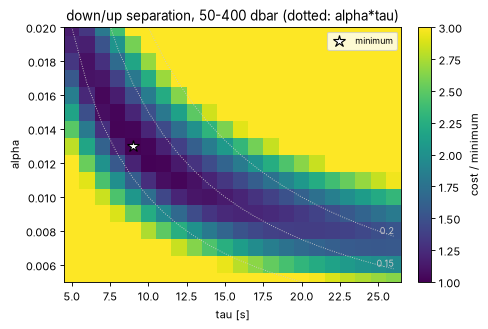

In [14]:
alphas = np.arange(0.005, 0.0201, 0.001)
taus = np.arange(5, 26.01, 1)  # s, beta = 1/tau; must not contain 0
cm_tm = tc.thermal_mass_cost_map(tm_base, alphas, taus, tm_cost, casts=tm_casts, tbins=tm_tbins)
best = check_minimum(cm_tm, ["alpha", "tau"], ["", "s"])
alpha, tau = best["alpha"], best["tau"]
beta = 1 / tau

tm_corr = with_sp(tc.correct(tm_ctd, lag=lag, tau_t=tau_t, lowpass=lowpass, thermal_mass=True, alpha=alpha, beta=beta))
tm_sep1 = tc.downup_separation(tm_corr, tm_casts, tm_tbins, pmin=TM_PBAND[0], pmax=TM_PBAND[1])
print(f"separation {tm_sep0.attrs['mean']:.4f} -> {tm_sep1.attrs['mean']:.4f} with alpha {alpha:.3f}, tau {tau:.0f} s")
print(f"alpha * tau = {alpha * tau:.3f} s")
if n_pairs < 10:
    print(f"PLACEHOLDER: only {n_pairs} pairs; refit alpha and beta on a deployment with many down/up pairs")

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
pc = ax.pcolormesh(cm_tm.tau, cm_tm.alpha, cm_tm.cost / cm_tm.cost.min(), vmin=1, vmax=3, cmap="viridis")
fig.colorbar(pc, ax=ax, label="cost / minimum")
for prod in [0.1, 0.15, 0.2]:
    ax.plot(taus, prod / taus, color="0.8", lw=0.8, ls=":")
    ax.annotate(f"{prod}", (taus[-1], prod / taus[-1]), color="0.8", fontsize=8, ha="right", va="bottom")
ax.plot(tau, alpha, "*", color="w", mec="k", ms=11, label="minimum")
ax.set(xlabel="tau [s]", ylabel="alpha", ylim=(alphas[0], alphas[-1]),
       title=f"down/up separation, {TM_PBAND[0]}-{TM_PBAND[1]} dbar (dotted: alpha*tau)")
ax.legend(loc="upper right", fontsize=8);

The trough runs roughly along lines of constant `alpha * tau`, so the product is better constrained than `alpha` and `tau` apart.
The MOTIVE fleet uses a pressure profile of `alpha * tau` at `beta = 1/12` s in place of a scalar `alpha`.
It is shown here as reference only.
It was built from thermal-mass scans of three SBE49s (0387, 0537, 0674) over both MOTIVE cruises (motive-cruise-proc drafts/34).
On RR2410 it over-corrects at 500 to 900 dbar (motive-cruise-proc drafts/45), so it is not a default.
A pressure profile needs many deep down/up pairs, ideally across instruments.


In [15]:
print("MOTIVE fleet profile, reference only (beta = 1/12 s):")
for p, prod in zip(REF_TM_PROFILE["p"], REF_TM_PROFILE["product"], strict=True):
    mark = "  <- in TM_PBAND" if TM_PBAND[0] <= p <= TM_PBAND[1] else ""
    print(f"  {p:6.0f} dbar  alpha*tau {prod:.3f} s{mark}")
print(f"fitted here: alpha*tau {alpha * tau:.3f} s over {TM_PBAND[0]}-{TM_PBAND[1]} dbar, from {n_pairs} pairs")

MOTIVE fleet profile, reference only (beta = 1/12 s):
      75 dbar  alpha*tau 0.120 s  <- in TM_PBAND
     125 dbar  alpha*tau 0.124 s  <- in TM_PBAND
     175 dbar  alpha*tau 0.100 s  <- in TM_PBAND
     250 dbar  alpha*tau 0.118 s  <- in TM_PBAND
     350 dbar  alpha*tau 0.154 s  <- in TM_PBAND
     450 dbar  alpha*tau 0.169 s
     600 dbar  alpha*tau 0.195 s
     800 dbar  alpha*tau 0.232 s
    1000 dbar  alpha*tau 0.237 s
fitted here: alpha*tau 0.117 s over 50-400 dbar, from 2 pairs


## 5. Chi gain

The microconductivity channel `c1` needs a gain that converts volts to conductivity.
`fit_gain_casts` matches the `c1` spectrum to the SBE49 `c` spectrum at low wavenumber (0.05 to 0.5 cpm) on each down cast and returns one gain per cast.
The gain for `fctd.yml` is the median over down casts.
`load_c1` reads `efe/c1` from the L0 files and splits it into gap-free ranges.
The fit uses `c` with the section 4 T-C corrections applied, the same `c` that `add_chi` sees in section 6 (motive-cruise-proc drafts/12 also fitted on corrected products).


In [16]:
# corrected c on the first-pass time axis, as make_l1 builds it in section 6
c_corr = tc.correct(ctd, lag=lag, tau_t=tau_t, lowpass=lowpass, thermal_mass=True, alpha=alpha, beta=beta).c
ctd_corr = ctd.assign(c=c_corr)
c1, c1_ranges = load_c1(l0_files)
fits = fit_gain_casts(ctd_corr, c1, c1_ranges, casts, ChiParams())
del c1
print(fits.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
gain = float(fits.gain.median())
print(f"\ngain {gain:.2f} (median of {len(fits)} down casts of {n_down})")


 cast  gain  spd  n_ctd  n_c1
    1  9.25 4.08   3938 80099
    2  5.58 2.71   2768 56295

gain 7.42 (median of 2 down casts of 2)


### Chi settings

Besides the gain, three chi settings differ from the modfish defaults in `fctd_example.yml`, which `fctd.yml` inherits.
The defaults are unchanged in modfish.

- `rail_lo: 0.05` V and `rail_hi: 2.45` V (defaults 0.001 and 2.499 V). On MOTIVE, raw `c1` made excursions to within a few mV of the ADC limits, which the default thresholds did not catch (motive-cruise-proc drafts/41).
- `min_bins: 3`. The default 4 acted as a 0.64 m/s fall-rate cut on MOTIVE (motive-cruise-proc drafts/43).


## 6. Write `fctd.yml` and reprocess with chi

The fitted values go into a copy of the template, written to `work_dir/fctd.yml`.
`FCTDConfig.from_yaml` loads it back, which also checks every key.
`process_deployment` then rebuilds the products with the T-C corrections and chi on.
The YAML dump drops the template's comments; `fctd_example.yml` keeps them.

In [17]:
with open(template) as f:
    params = yaml.safe_load(f)
params["latitude_fallback"] = latitude_fallback
params["tc"].update(
    lag=round(lag, 4), tau_t=round(tau_t, 4), lowpass=float(lowpass),
    thermal_mass=True, alpha=round(alpha, 4), beta=round(beta, 6),
)
params["chi"].update(
    enabled=True, gain=round(gain, 3),
    gain_source=f"fctd_processing.ipynb, median of {len(fits)} fitted down casts of {name}",
)
config_path = work_dir / "fctd.yml"
with open(config_path, "w") as f:
    f.write(f"# FCTD config for {name}, written by fctd_processing.ipynb from {template.name}\n")
    yaml.safe_dump(params, f, sort_keys=False)

cfg = fctd.FCTDConfig.from_yaml(config_path)
print(f"wrote {config_path}")
print("tc:", {k: params["tc"][k] for k in ["lag", "tau_t", "lowpass", "thermal_mass", "alpha", "beta"]})
print("chi:", {k: params["chi"][k] for k in ["enabled", "gain", "rail_lo", "rail_hi", "min_bins"]})

wrote data/fctd.yml
tc: {'lag': 0.035, 'tau_t': 0.05, 'lowpass': 5.0, 'thermal_mass': True, 'alpha': 0.013, 'beta': 0.111111}
chi: {'enabled': True, 'gain': 7.416, 'rail_lo': 0.05, 'rail_hi': 2.45, 'min_bins': 3}


### Fitted values against the MOTIVE reference

MOTIVE fitted the 0537 T-C values on deployments d09 and d12 (motive-cruise-proc drafts/04).
The MOTIVE gain 7.49 is a fit on the same two d08 down casts, from the corrected product (motive-cruise-proc drafts/12).
Use the MOTIVE values as a plausibility check only.


In [18]:
rows = [("lag [s]", lag, REF["lag"]), ("tau_t [s]", tau_t, REF["tau_t"]),
        ("lowpass [Hz]", lowpass, REF["lowpass"]), ("chi gain", gain, REF["gain"])]
print(f"{'':14s}{'fitted':>9s}{'MOTIVE':>9s}{'diff':>9s}")
for label, fitted, ref in rows:
    print(f"{label:14s}{fitted:9.3f}{ref:9.3f}{fitted - ref:+9.3f}")
print(f"{'alpha*tau [s]':14s}{alpha * tau:9.3f}   profile {min(REF_TM_PROFILE['product']):.3f} to "
      f"{max(REF_TM_PROFILE['product']):.3f} over {REF_TM_PROFILE['p'][0]:.0f} to {REF_TM_PROFILE['p'][-1]:.0f} dbar")

                 fitted   MOTIVE     diff
lag [s]           0.035    0.030   +0.005
tau_t [s]         0.050    0.050   +0.000
lowpass [Hz]      5.000    5.000   +0.000
chi gain          7.416    7.490   -0.074
alpha*tau [s]     0.117   profile 0.100 to 0.237 over 75 to 1000 dbar


In [19]:
l1_path, grid_path = fctd.process_deployment(l0_files, proc_dir, name, config=cfg, overwrite=True)
print(l1_path, grid_path, sep="\n")

WARNING modfish.fctd.concat: FCTD25_12_08_133647.nc and FCTD25_12_08_134303.nc overlap by 20.4 s
WARNING modfish.fctd.concat: FCTD25_12_08_134303.nc and FCTD25_12_08_134911.nc overlap by 20.5 s
WARNING modfish.fctd.concat: FCTD25_12_08_134911.nc and FCTD25_12_08_135519.nc overlap by 20.1 s
INFO modfish.fctd.casts: find_casts: 2 candidate run(s) rejected by min_range=10.0/min_duration=10.0


data/proc/fctd_d08_l1.nc
data/proc/fctd_d08_grid.nc


## 7. Products

The L1 file is a `DataTree`: the corrected `ctd` time series with cast labels, the `casts` table, the other L0 streams on their own time bases, and, with chi on, a `chi` group of 2 s windows every 0.25 s.
The grid file is a `Dataset` on `(depth, cast)` with `dz` bins.

In [20]:
with xr.open_datatree(l1_path) as l1:
    summarize_tree(l1)
    chi = l1["chi"].to_dataset(inherit=False).load()
    ctd1 = l1["ctd"].to_dataset().load()
grid = xr.open_dataset(grid_path).load()
print(f"\ngrid: {dict(grid.sizes)}, dz {grid.attrs.get('dz')} m")
print("variables:", ", ".join(grid.data_vars))

/ctd     (time 21572): p, t, c, lat, lon, depth, dPdt, t_raw, c_raw, SP, SA, CT, sgth0
/casts   (cast 4): start_time, end_time, direction
/efe     (time 439200): t1, t2, f1, c1, a1, a2, a3
/ecop    (time 29463): bb, chla, fdom
/gps     (time 1356): lat, lon
/chi     (time 5415): depth, p, lon, lat, spd, chi, phi, kmax, n_bins, range_id, chi_flag, direction, n2, Tz, Sz, Rrho, chi_tot, eps_chi, r

grid: {'depth': 2955, 'cast': 4}, dz 0.5 m
variables: p, t, c, dPdt, t_raw, c_raw, SP, SA, CT, sgth0, chi, chi_tot, eps_chi, r, kmax, phi, chi_flag


### Corrected down/up separation

The same plot as section 3, from the corrected L1 `ctd` group.

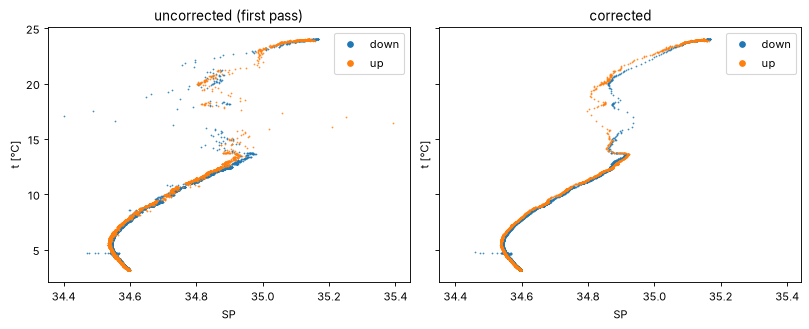

In [21]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True, constrained_layout=True)
plot_ts(ax0, ctd, casts, title="uncorrected (first pass)")
plot_ts(ax1, ctd1, casts, title="corrected");

### Section

Temperature, salinity and chi from the grid, one column per cast.
Chi is averaged as log10 over 10 m (20 bins of 0.5 m) for the plot, since at this fall rate most 0.5 m bins hold no window.


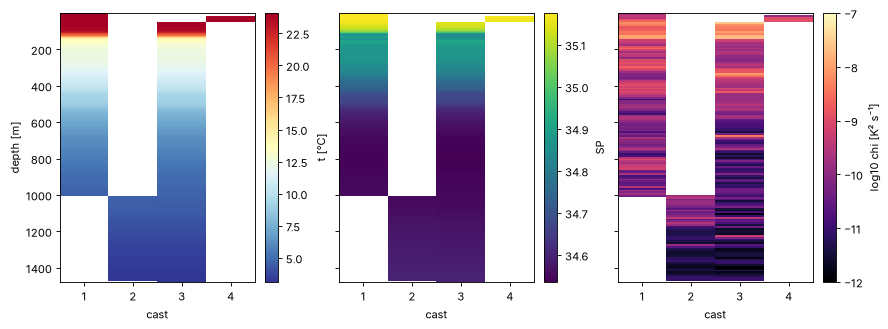

In [22]:
nbin = 20  # 0.5 m bins per plotted chi bin
log_chi = np.log10(grid.chi).coarsen(depth=nbin, boundary="trim").mean()
fig, axs = plt.subplots(1, 3, figsize=(11, 4), sharey=True, constrained_layout=True)
for ax, (v, label, kw) in zip(axs, [
    (grid.t, "t [°C]", dict(cmap="RdYlBu_r")),
    (grid.SP, "SP", dict(cmap="viridis")),
    (log_chi, "log10 chi [K² s⁻¹]", dict(cmap="magma", vmin=-12, vmax=-7)),
], strict=True):
    pc = ax.pcolormesh(v.cast, v.depth, v, **kw)
    fig.colorbar(pc, ax=ax, label=label)
    ax.set(xlabel="cast", xticks=grid.cast.values)
axs[0].invert_yaxis()
axs[0].set_ylabel("depth [m]");


### Chi flags

`chi_flag` is a bitmask per window. The table counts the windows with each bit set; a window can carry several bits.
The grid leaves windows with bits 1 (slow), 4 (band empty) or 32 (rail) out of every chi bin mean.
Bits in `grid.closure_exclude_flags` also leave a window out of the `chi_tot`, `eps_chi` and `r` means.
Bit 2 (noise-dominated) excludes nothing, since a small signal is a valid estimate.
The gridded `chi_flag` is the bitwise or over all windows in a bin, including excluded ones.

In [23]:
flag = chi.chi_flag.values.astype(np.uint8)
n = flag.size
meanings = dict(item.split(" ", 1) for item in chi_config.FLAG_MEANINGS.split(", "))
print(f"{n} chi windows, {np.isfinite(chi.chi.values).sum()} with finite chi")
for bit, meaning in meanings.items():
    k = int(((flag & np.uint8(int(bit))) != 0).sum())
    print(f"  bit {bit:>3s} {meaning:20s} {k:6d} ({100 * k / n:5.1f} %)")

excl = (flag & np.uint8(chi_config.FLAG_SLOW | chi_config.FLAG_EMPTY | chi_config.FLAG_RAIL)) != 0
closure_bits = np.uint8(grid.attrs.get("closure_exclude_flags", 0))
excl_closure = excl | ((flag & closure_bits) != 0)
print(f"\nexcluded from every chi mean: {excl.sum()} windows ({100 * excl.sum() / n:.1f} %)")
print(f"excluded from chi_tot, eps_chi, r (closure_exclude_flags {int(closure_bits)}): "
      f"{excl_closure.sum()} windows ({100 * excl_closure.sum() / n:.1f} %)")

5415 chi windows, 3470 with finite chi
  bit   1 slow                   1944 ( 35.9 %)
  bit   2 noise_dominated         240 (  4.4 %)
  bit   4 band_empty                0 (  0.0 %)
  bit   8 eps_table_edge           55 (  1.0 %)
  bit  16 n2_not_positive         122 (  2.3 %)
  bit  32 rail                     99 (  1.8 %)
  bit  64 no_closure_inputs         1 (  0.0 %)
  bit 128 rrho_capped              88 (  1.6 %)

excluded from every chi mean: 1971 windows (36.4 %)
excluded from chi_tot, eps_chi, r (closure_exclude_flags 0): 1971 windows (36.4 %)
